# ConsenDxFormer

This notebook is for a short, honest demonstration in Jupyter. It shows the code version, the actual configuration found on the server, the implemented components, saved results, and GPU availability.

**Safety rule:** this notebook does not start training. A new GPU training run must be separately authorised, recorded, and saved in a new artifact directory.

In [1]:
from pathlib import Path
import json
import re
import subprocess

PROJECT_ROOT = Path('/experiment-storage/chaidir/fawad-dsai/GLADS_CT Project/03_ConsenDxFormer_and_Datasets/ConsenDxFormer')
assert PROJECT_ROOT.is_dir(), f'Project not found: {PROJECT_ROOT}'
print('PROJECT_ROOT =', PROJECT_ROOT)

PROJECT_ROOT = /experiment-storage/chaidir/fawad-dsai/GLADS_CT Project/03_ConsenDxFormer_and_Datasets/ConsenDxFormer


## 1. Confirm the exact repository version

Show this first. It proves which code version you are presenting and whether the working tree is clean.

In [2]:
def git(*args):
    return subprocess.run(['git', *args], cwd=PROJECT_ROOT, text=True, capture_output=True, check=True).stdout.strip()

print('Branch :', git('branch', '--show-current'))
print('Commit :', git('rev-parse', '--short', 'HEAD'))
status = git('status', '--short')
print('Status :', 'CLEAN' if not status else status)

Branch : phase4-consendxformer
Commit : 4141ae7
Status : ?? .ipynb_checkpoints/
?? ConsenDxFormer_Supervisor_Demo (3).ipynb
?? validation/phase5_candidate_c/.ipynb_checkpoints/


## 2. Show GPU availability

This only checks the environment. It does not run the model.

In [3]:
import torch

print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        print(f'GPU {i}: {torch.cuda.get_device_name(i)}')

PyTorch: 2.3.0+cu121
CUDA available: True
GPU 0: NVIDIA GeForce RTX 2080 Ti
GPU 1: NVIDIA GeForce RTX 2080 Ti
GPU 2: NVIDIA GeForce RTX 2080 Ti
GPU 3: NVIDIA GeForce RTX 2080 Ti


## 3. Discover the actual training configuration

This cell finds the real values stored in the current configuration and source files.

In [4]:
terms = re.compile(r'epoch|batch|learning.?rate|\blr\b|weight.?decay|dropout|patience|seed|lambda|ordinal|attention|head|layer|embed', re.I)
files = []
for folder in ['configs', 'scripts', 'src']:
    root = PROJECT_ROOT / folder
    if root.exists():
        files.extend(p for p in root.rglob('*') if p.suffix in {'.json', '.yaml', '.yml', '.py'})

matches = []
for path in files:
    try:
        for line_no, line in enumerate(path.read_text(errors='replace').splitlines(), start=1):
            if terms.search(line):
                matches.append((path.relative_to(PROJECT_ROOT), line_no, line.strip()))
    except OSError:
        pass

for path, line_no, line in matches[:180]:
    print(f'{path}:{line_no}: {line}')
print(f'\nDisplayed {min(len(matches), 180)} of {len(matches)} matching lines.')

configs/phase5_insertion_deletion_v1.json:13: "seeds": [
configs/phase5_insertion_deletion_v1.json:26: "attention_reference_id": "phase4-evaluation-22cb656eabd040c2",
configs/phase5_insertion_deletion_v1.json:111: "per_seed_summaries": 36,
configs/phase5_insertion_deletion_v1.json:120: "batch_size": 1,
configs/phase5_insertion_deletion_v1.json:128: "unit_order": "model_then_seed_then_original_archive_row",
configs/phase5_insertion_deletion_v1.json:140: "per_seed": 139080
configs/phase5_insertion_deletion_v1.json:149: "seed": 42,
configs/phase5_insertion_deletion_v1.json:157: "seed": 43,
configs/phase5_insertion_deletion_v1.json:165: "seed": 44,
configs/phase5_insertion_deletion_v1.json:172: "hypothesis_id": "C_attention_off_42",
configs/phase5_insertion_deletion_v1.json:173: "seed": 42,
configs/phase5_insertion_deletion_v1.json:174: "comparator": "attention_alignment_off",
configs/phase5_insertion_deletion_v1.json:180: "hypothesis_id": "C_attention_off_43",
configs/phase5_insertion_del

### Expected locked settings to confirm

- Input: 64 × 64 nodule crop; batch size: 32; maximum epochs: 100
- Adam, learning rate: 0.0001, weight decay: 0.00001; dropout: 0.5
- Early-stopping patience: 10; ReduceLROnPlateau; gradient clipping: 1.0
- Seeds: 42, 43, 44
- CNN channels: [32, 64, 128]; embedding: 128; 4 heads; 2 Transformer layers; MLP ratio: 4
- Ordinal-loss weight: 0.5; attention-loss weight: 0.05

If the discovered configuration differs, the discovered server configuration is the value to report.

In [5]:
# Presentation-ready hyperparameter table. Confirm these values against the discovery cell above.
import pandas as pd
hyperparameters = [
    ('Input image', '64 × 64 pre-cropped nodule image'),
    ('Batch size', 32),
    ('Maximum epochs', 100),
    ('Optimizer', 'Adam'),
    ('Learning rate', '0.0001 (1e-4)'),
    ('Weight decay', '0.00001 (1e-5)'),
    ('Dropout', 0.5),
    ('Early-stopping patience', '10 epochs'),
    ('Learning-rate scheduler', 'ReduceLROnPlateau'),
    ('Gradient clipping', 1.0),
    ('Random seeds', '42, 43, 44'),
    ('CNN channels', '[32, 64, 128]'),
    ('Embedding size', 128),
    ('Transformer heads / layers', '4 heads / 2 layers'),
    ('MLP ratio', 4),
    ('Ordinal-loss weight', 0.5),
    ('Attention-loss weight', 0.05),
]
display(pd.DataFrame(hyperparameters, columns=['Training setting', 'Configured value']))
print('Use the configuration-discovery output above as the final authority for the current server code.')

,Training setting,Configured value
0,Input image,64 × 64 pre-cropped nodule image
1,Batch size,32
2,Maximum epochs,100
3,Optimizer,Adam
4,Learning rate,0.0001 (1e-4)
5,Weight decay,0.00001 (1e-5)
6,Dropout,0.5
7,Early-stopping patience,10 epochs
8,Learning-rate scheduler,ReduceLROnPlateau
9,Gradient clipping,1.0


Use the configuration-discovery output above as the final authority for the current server code.


## 4. Show the implemented ConsenDxFormer components

The components exist in code: disagreement-aware learning, ordinal supervision, attention guidance, and hierarchical fusion.

In [6]:
keywords = re.compile(r'disagreement|ordinal|attention|fusion|consensus', re.I)
for path in sorted((PROJECT_ROOT / 'src').rglob('*.py')):
    lines = path.read_text(errors='replace').splitlines()
    hit_lines = [(i + 1, line.strip()) for i, line in enumerate(lines) if keywords.search(line)]
    if hit_lines:
        print(f'\n--- {path.relative_to(PROJECT_ROOT)} ---')
        for line_no, line in hit_lines[:20]:
            print(f'{line_no}: {line}')


--- src/consendxformer/baseline_config.py ---
21: "attention_dropout": 0.1,
25: "use_spatial_attention": True,
26: "fusion_type": "concat",
27: "use_raw_transformer_in_fusion": False,
48: ("evaluation", "save_confusion_matrix"): True,

--- src/consendxformer/baseline_evaluation.py ---
3: The confusion-matrix convention is rows=true class and columns=predicted class.
302: confusion = np.zeros((len(CLASS_ORDER), len(CLASS_ORDER)), dtype=np.int64)
303: np.add.at(confusion, (true_indices, predicted_indices), 1)
311: true_positive = int(confusion[class_index, class_index])
312: predicted_total = int(confusion[:, class_index].sum())
313: support = int(confusion[class_index, :].sum())
336: confusion_json = [[int(value) for value in row] for row in confusion.tolist()]
337: return per_class, confusion_json, macro
401: per_class, confusion, macro = _classification_metrics(
459: "confusion_matrix": confusion,

--- src/consendxformer/lidc_ledger.py ---
47: "disagreement_entropy",
48: "ordinal_t1"

## 5. Show the verified comparison result

These are saved historical results from the fixed three-seed comparison. They are not a new live training result.

In [7]:
comparison = {
    'Metric': ['Accuracy', 'Macro-F1', 'Indeterminate recall'],
    'LungDxFormer B1': [66.85, 67.24, 68.29],
    'ConsenDxFormer': [66.12, 66.76, 71.54],
    'Difference (percentage points)': [-0.73, -0.48, 3.25],
}
try:
    import pandas as pd
    display(pd.DataFrame(comparison))
except ImportError:
    print(json.dumps(comparison, indent=2))

print('Conclusion: indeterminate recall improved, but accuracy and macro-F1 did not improve.')
print('The paired statistical comparisons were non-rejections: no superiority claim is justified.')

,Metric,LungDxFormer B1,ConsenDxFormer,Difference (percentage points)
0,Accuracy,66.85,66.12,-0.73
1,Macro-F1,67.24,66.76,-0.48
2,Indeterminate recall,68.29,71.54,3.25


Conclusion: indeterminate recall improved, but accuracy and macro-F1 did not improve.
The paired statistical comparisons were non-rejections: no superiority claim is justified.


## 6. Open the saved project report and result artifacts

Use these files to show the written evidence. If a file is missing, the notebook prints the available nearby files instead of failing.

In [8]:
report = PROJECT_ROOT / 'docs' / 'phase5_paired_correctness_results.md'
if report.exists():
    print(report.read_text(errors='replace')[:8000])
else:
    print('Report not found. Available Phase 5 documentation:')
    for path in sorted((PROJECT_ROOT / 'docs').glob('*phase5*')):
        print(path.name)

print('\nAvailable paired-correctness artifact directories:')
artifact_root = PROJECT_ROOT / 'artifacts' / 'phase5' / 'paired_correctness'
if artifact_root.exists():
    for path in sorted(artifact_root.iterdir()):
        if path.is_dir():
            print(path.name)

Report not found. Available Phase 5 documentation:
phase5_candidate_c_core_validation.md
phase5_descriptive_subset.md
phase5_inference_amendment_decision.md
phase5_inference_implementation_authorization.md
phase5_inference_integration.md
phase5_inference_resolution_proposal.md
phase5_insertion_deletion_subset.md
phase5_supplemental_evaluation_proposal.md
phase5_synthetic_timing.md

Available paired-correctness artifact directories:
.ipynb_checkpoints
phase5-inference-preflight-5b67b8e275de62f5
phase5-inference-preflight-f817aa9732d04827
phase5-inference-results-79f6f8de6cab19b6


## 7. Show saved nodule classifications

This cell loads saved predictions from the completed Phase 5 result bundle. It does not generate a new prediction. Select a row, then show its case identifier, true label, predicted label and any saved probability values.

In [9]:
prediction_files = sorted(artifact_root.glob('phase5-inference-results-*/saved_predictions.json'), key=lambda p: p.stat().st_mtime, reverse=True)
assert prediction_files, 'No saved_predictions.json found in a Phase 5 result bundle.'
prediction_file = prediction_files[0]
payload = json.loads(prediction_file.read_text())
print('Using:', prediction_file)
print('Top-level type:', type(payload).__name__)
if isinstance(payload, dict):
    print('Top-level keys:', list(payload)[:30])

def record_lists(obj, path='root'):
    found = []
    if isinstance(obj, list) and obj and all(isinstance(item, dict) for item in obj):
        key_text = ' '.join(str(k).lower() for item in obj[:3] for k in item)
        if any(word in key_text for word in ['prediction', 'predicted', 'label', 'class', 'probability']):
            found.append((path, obj))
    elif isinstance(obj, dict):
        for key, value in obj.items():
            found.extend(record_lists(value, f'{path}.{key}'))
    elif isinstance(obj, list):
        for index, value in enumerate(obj[:20]):
            found.extend(record_lists(value, f'{path}[{index}]'))
    return found

lists = record_lists(payload)
assert lists, 'The saved file contains no recognisable prediction-record list. Inspect the printed keys above.'
record_path, records = max(lists, key=lambda item: len(item[1]))
print(f'Record list: {record_path}; rows: {len(records)}')

import pandas as pd
prediction_table = pd.DataFrame(records)
display(prediction_table.head(10))

Using: /experiment-storage/chaidir/fawad-dsai/GLADS_CT Project/03_ConsenDxFormer_and_Datasets/ConsenDxFormer/artifacts/phase5/paired_correctness/phase5-inference-results-79f6f8de6cab19b6/saved_predictions.json
Top-level type: dict
Top-level keys: ['expected_identities', 'records']
Record list: root.expected_identities; rows: 183


,nodule_id,patient_id,series_instance_uid,split,true_class
0,LIDC-IDRI-0001__nodule-b3a6d02a8169b300,LIDC-IDRI-0001,1.3.6.1.4.1.14519.5.2.1.6279.6001.179049373636...,test,malignant
1,LIDC-IDRI-0016__nodule-1022926dc3910453,LIDC-IDRI-0016,1.3.6.1.4.1.14519.5.2.1.6279.6001.153536305742...,test,malignant
2,LIDC-IDRI-0016__nodule-4446df64f1743087,LIDC-IDRI-0016,1.3.6.1.4.1.14519.5.2.1.6279.6001.153536305742...,test,malignant
3,LIDC-IDRI-0016__nodule-7167255b8ba86892,LIDC-IDRI-0016,1.3.6.1.4.1.14519.5.2.1.6279.6001.153536305742...,test,malignant
4,LIDC-IDRI-0023__nodule-ad9d8189f221dd6b,LIDC-IDRI-0023,1.3.6.1.4.1.14519.5.2.1.6279.6001.487745546557...,test,malignant
5,LIDC-IDRI-0024__nodule-5d17cf1fa7df5ba5,LIDC-IDRI-0024,1.3.6.1.4.1.14519.5.2.1.6279.6001.206028343897...,test,benign
6,LIDC-IDRI-0024__nodule-9bd55d601067e1b3,LIDC-IDRI-0024,1.3.6.1.4.1.14519.5.2.1.6279.6001.206028343897...,test,benign
7,LIDC-IDRI-0027__nodule-0e26807038c351b8,LIDC-IDRI-0027,1.3.6.1.4.1.14519.5.2.1.6279.6001.183843376225...,test,indeterminate
8,LIDC-IDRI-0045__nodule-0211d7de773d8486,LIDC-IDRI-0045,1.3.6.1.4.1.14519.5.2.1.6279.6001.910435939545...,test,indeterminate
9,LIDC-IDRI-0045__nodule-6c848b1514b7d3a2,LIDC-IDRI-0045,1.3.6.1.4.1.14519.5.2.1.6279.6001.910435939545...,test,malignant


,Field,Saved value
0,nodule_id,LIDC-IDRI-0024__nodule-5d17cf1fa7df5ba5
1,patient_id,LIDC-IDRI-0024
2,series_instance_uid,1.3.6.1.4.1.14519.5.2.1.6279.6001.206028343897...
3,split,test
4,true_class,benign


Displayed image: /experiment-storage/chaidir/fawad-dsai/data/raw/lidc_idri_full/lidc_idri/LIDC-IDRI-0810/1.3.6.1.4.1.14519.5.2.1.6279.6001.225336514441526266989689082116/1.3.6.1.4.1.14519.5.2.1.6279.6001.114914167428485563471327801935/c334f890-f767-4342-9c09-14c2a1451921.dcm


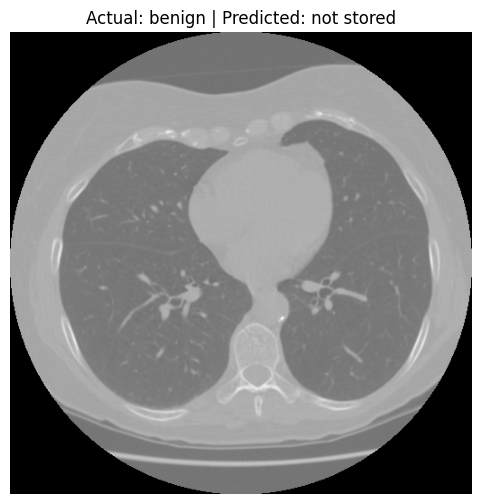

Columns:
['nodule_id', 'patient_id', 'series_instance_uid', 'split', 'true_class']


,nodule_id,patient_id,series_instance_uid,split,true_class
0,LIDC-IDRI-0001__nodule-b3a6d02a8169b300,LIDC-IDRI-0001,1.3.6.1.4.1.14519.5.2.1.6279.6001.179049373636...,test,malignant
1,LIDC-IDRI-0016__nodule-1022926dc3910453,LIDC-IDRI-0016,1.3.6.1.4.1.14519.5.2.1.6279.6001.153536305742...,test,malignant
2,LIDC-IDRI-0016__nodule-4446df64f1743087,LIDC-IDRI-0016,1.3.6.1.4.1.14519.5.2.1.6279.6001.153536305742...,test,malignant
3,LIDC-IDRI-0016__nodule-7167255b8ba86892,LIDC-IDRI-0016,1.3.6.1.4.1.14519.5.2.1.6279.6001.153536305742...,test,malignant
4,LIDC-IDRI-0023__nodule-ad9d8189f221dd6b,LIDC-IDRI-0023,1.3.6.1.4.1.14519.5.2.1.6279.6001.487745546557...,test,malignant



Selected record:
{'nodule_id': 'LIDC-IDRI-0024__nodule-5d17cf1fa7df5ba5', 'patient_id': 'LIDC-IDRI-0024', 'series_instance_uid': '1.3.6.1.4.1.14519.5.2.1.6279.6001.206028343897359374907954580114', 'split': 'test', 'true_class': 'benign'}


In [18]:
# Change this row number to show another saved classification.
EXAMPLE_ROW = 5
# Leave blank unless automatic matching cannot find the correct image.
MANUAL_IMAGE_PATH = ''

example = prediction_table.iloc[EXAMPLE_ROW]
display(pd.DataFrame({'Field': example.index, 'Saved value': example.values}))

image_extensions = {'.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff', '.dcm'}
def usable_image(value):
    try:
        path = Path(str(value))
        return path if path.is_file() and path.suffix.lower() in image_extensions else None
    except (TypeError, OSError):
        return None

image_path = usable_image(MANUAL_IMAGE_PATH) if MANUAL_IMAGE_PATH else None
if image_path is None:
    path_keys = [key for key in example.index if any(word in str(key).lower() for word in ['image', 'path', 'file'])]
    image_path = next((usable_image(example[key]) for key in path_keys if usable_image(example[key]) is not None), None)

# Fallback: search likely local data roots using the saved case, patient or nodule identifiers.
if image_path is None:
    identifier_keys = [key for key in example.index if any(word in str(key).lower() for word in ['case', 'patient', 'nodule', 'series', 'uid', 'id'])]
    tokens = []
    for key in identifier_keys:
        tokens.extend(re.findall(r'[A-Za-z0-9_-]{4,}', str(example[key])))
    tokens = list(dict.fromkeys(tokens))[:12]
    search_roots = [PROJECT_ROOT / 'data', PROJECT_ROOT.parent / 'data']
    for root in search_roots:
        if not root.is_dir() or image_path is not None:
            continue
        for token in tokens:
            result = subprocess.run(['find', str(root), '-type', 'f', '-iname', f'*{token}*', '-print', '-quit'], text=True, capture_output=True)
            candidate = usable_image(result.stdout.strip())
            if candidate is not None:
                image_path = candidate
                break

# Second fallback: look for a metadata CSV that links this saved identifier to an image path.
if image_path is None:
    record_values = {str(value) for value in example.values if str(value) not in {'', 'nan', 'None'}}
    csv_roots = [PROJECT_ROOT / 'artifacts', PROJECT_ROOT / 'data', PROJECT_ROOT.parent / 'data']
    csv_files = []
    for root in csv_roots:
        if root.is_dir():
            csv_files.extend(list(root.rglob('*.csv'))[:150])
    for csv_path in csv_files[:300]:
        try:
            header = pd.read_csv(csv_path, nrows=0)
            path_columns = [c for c in header.columns if any(word in str(c).lower() for word in ['image', 'path', 'file'])]
            id_columns = [c for c in header.columns if any(word in str(c).lower() for word in ['case', 'patient', 'nodule', 'series', 'uid', 'id'])]
            if not path_columns or not id_columns:
                continue
            table = pd.read_csv(csv_path, dtype=str)
            matched = table[table[id_columns].astype(str).isin(record_values).any(axis=1)]
            for _, matched_row in matched.iterrows():
                for column in path_columns:
                    candidate = usable_image(matched_row[column])
                    if candidate is not None:
                        image_path = candidate
                        print('Matched through metadata:', csv_path)
                        break
                if image_path is not None:
                    break
        except Exception:
            continue
        if image_path is not None:
            break

if image_path is None:
    print('No verified image-to-prediction mapping was found. Do not present an unrelated photo as this classification.')
    print('Set MANUAL_IMAGE_PATH to the exact nodule image path, then rerun this cell.')
else:
    import matplotlib.pyplot as plt
    if image_path.suffix.lower() == '.dcm':
        import pydicom
        image = pydicom.dcmread(image_path).pixel_array
        if image.ndim == 3:
            image = image[image.shape[0] // 2]
    else:
        from PIL import Image
        image = Image.open(image_path)
    plt.figure(figsize=(6, 6))
    plt.imshow(image, cmap='gray')
    plt.axis('off')
    true_value = next((example[k] for k in example.index if 'true' in str(k).lower() or 'target' in str(k).lower() or 'label' in str(k).lower()), 'not stored')
    pred_value = next((example[k] for k in example.index if 'pred' in str(k).lower()), 'not stored')
    plt.title(f'Actual: {true_value} | Predicted: {pred_value}')
    print('Displayed image:', image_path)
    plt.show()
print("Columns:")
print(prediction_table.columns.tolist())

display(prediction_table.head(5))

print("\nSelected record:")
print(example.to_dict())

“This is a saved classification from the frozen evaluation result. The table shows the true label and the model’s predicted class. I can switch rows to inspect other saved cases. This is evidence of completed evaluation, not a new live training result.”

In [19]:
print("Columns:")
print(prediction_table.columns.tolist())

display(prediction_table.head(5))

print("\nSelected record:")
print(example.to_dict())

Columns:
['nodule_id', 'patient_id', 'series_instance_uid', 'split', 'true_class']


,nodule_id,patient_id,series_instance_uid,split,true_class
0,LIDC-IDRI-0001__nodule-b3a6d02a8169b300,LIDC-IDRI-0001,1.3.6.1.4.1.14519.5.2.1.6279.6001.179049373636...,test,malignant
1,LIDC-IDRI-0016__nodule-1022926dc3910453,LIDC-IDRI-0016,1.3.6.1.4.1.14519.5.2.1.6279.6001.153536305742...,test,malignant
2,LIDC-IDRI-0016__nodule-4446df64f1743087,LIDC-IDRI-0016,1.3.6.1.4.1.14519.5.2.1.6279.6001.153536305742...,test,malignant
3,LIDC-IDRI-0016__nodule-7167255b8ba86892,LIDC-IDRI-0016,1.3.6.1.4.1.14519.5.2.1.6279.6001.153536305742...,test,malignant
4,LIDC-IDRI-0023__nodule-ad9d8189f221dd6b,LIDC-IDRI-0023,1.3.6.1.4.1.14519.5.2.1.6279.6001.487745546557...,test,malignant



Selected record:
{'nodule_id': 'LIDC-IDRI-0024__nodule-5d17cf1fa7df5ba5', 'patient_id': 'LIDC-IDRI-0024', 'series_instance_uid': '1.3.6.1.4.1.14519.5.2.1.6279.6001.206028343897359374907954580114', 'split': 'test', 'true_class': 'benign'}


## 8.run the model

1. Show this notebook’s repository and configuration checks first.
2. Explain that the saved Phase 4 and Phase 5 results are historical evidence from the frozen experiment.
3. Do not start 100-epoch training during the meeting without explicit approval. It creates a new experiment and must be logged separately.
4. If approval is given, first identify the real entry-point and its arguments using the cell below.

In [11]:
for folder in ['scripts', 'src']:
    root = PROJECT_ROOT / folder
    if root.exists():
        for path in sorted(root.rglob('*.py')):
            text = path.read_text(errors='replace')
            if 'argparse' in text or 'add_argument' in text or 'run_training' in text:
                print(path.relative_to(PROJECT_ROOT))

print('\nNext action only after approval: run the discovered entry-point with --help, then use the frozen configuration and one declared seed.')

scripts/00_lock_environment.py
scripts/01_prepare_locked_baseline.py
scripts/02_generate_patient_manifest.py
scripts/20_check_lidc_source.py
scripts/21_inventory_lidc.py
scripts/22_extract_lidc_nodules.py
scripts/23_render_lidc_rois.py
scripts/24_export_baseline_metadata.py
scripts/25_smoke_pylidc_runtime.py
scripts/46_evaluate_phase4_ablations.py
src/consendxformer/baseline_evaluator.py
src/consendxformer/baseline_runner.py
src/consendxformer/phase3_orchestrator.py
src/consendxformer/phase3_runner.py
src/consendxformer/phase4_ablation_launch.py
src/consendxformer/phase4_attention_comparison.py
src/consendxformer/phase4_evaluation_runner.py
src/consendxformer/phase4_evidence_gaps.py
src/consendxformer/phase4_posthoc_runner.py
src/consendxformer/phase4_runner.py
src/consendxformer/phase5_descriptive_runner.py
src/consendxformer/phase5_device.py
src/consendxformer/phase5_inference_runner.py
src/consendxformer/phase5_perturbation_runner.py
src/consendxformer/phase5_timing_runner.py

Next 